**Step 1:** Installs Gradio, the Python library used later to build a simple web interface for the image classifier.

In [1]:
%pip install gradio

Note: you may need to restart the kernel to use updated packages.


**Step 2:** Imports the libraries and Keras components needed for image processing, CNN construction, training, plotting, and loading a saved model.

In [2]:
import numpy as np
import gradio as gr
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.layers import Dense, Dropout, Convolution2D, MaxPooling2D, Flatten
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from keras.models import load_model
# from google.colab import drive

c:\Users\think\AppData\Local\Programs\Python\Python314\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**Optional:** This option connect to Google Colab.

In [3]:
# drive.mount('/content/drive')

**Step 4:** Sets the image size to 256 x 256 pixels, then creates a training data generator that rescales pixels and randomly rotates or flips images before loading them from `Dataset/Train`.

Note: Chuẩn bị ảnh để huấn luyện:
- Đặt kích thước ảnh thành 256 × 256.
- Đọc ảnh trong Train; mỗi thư mục con được xem là một lớp xe và nhãn được tạo tự động.
- Chia giá trị pixel cho 255 để đưa về khoảng 0–1.
- Xoay ảnh ngẫu nhiên tối đa 10 độ và lật ngang để tạo thêm biến thể dữ liệu.

In [4]:
image_size = 256
train_datagen = ImageDataGenerator(rescale=1 / 255, rotation_range=10, horizontal_flip=True)
train_generator = train_datagen.flow_from_directory('Dataset/Train', target_size=(image_size, image_size), class_mode="sparse")

Found 3352 images belonging to 7 classes.


**Step 5:** Reads 1 batch from the training generator, prints the pixel array of its first image for inspection, and stops immediately. The printed array can be very large.

Note: Lấy 1 batch từ bộ train, in toàn bộ mảng pixel của ảnh đầu tiên rồi dừng. Mặc định batch thường có 32 ảnh; cell này chỉ kiểm tra dữ liệu có được nạp và biến đổi hay không, không train model.

In [5]:
for image_batch, label_batch in train_generator:
    print(image_batch[0])
    break

[[[0.47450984 0.43921572 0.41176474]
  [0.47450984 0.43921572 0.41176474]
  [0.47450984 0.43921572 0.41176474]
  ...
  [0.45186824 0.47147608 0.48716235]
  [0.48372072 0.5033286  0.5190149 ]
  [0.4726695  0.49227735 0.5079636 ]]

 [[0.48269293 0.4473988  0.41994783]
  [0.48075777 0.44546366 0.41801268]
  [0.4788226  0.44352847 0.4160775 ]
  ...
  [0.45638365 0.4759915  0.49167776]
  [0.49081638 0.51042426 0.52611053]
  [0.4494474  0.46905524 0.4847415 ]]

 [[0.4969717  0.46167758 0.42887804]
  [0.49439147 0.45909736 0.4275879 ]
  [0.49181125 0.45651713 0.42629778]
  ...
  [0.46089906 0.4805069  0.49619317]
  [0.49791202 0.5175199  0.53320616]
  [0.42622527 0.44583312 0.4615194 ]]

 ...

 [[0.37011847 0.41325572 0.428942  ]
  [0.37398663 0.41712388 0.43281016]
  [0.38062313 0.42376038 0.43944666]
  ...
  [0.42376038 0.49042705 0.52964276]
  [0.42569557 0.49236223 0.53157794]
  [0.42763072 0.49429742 0.5335131 ]]

 [[0.3707635  0.4139008  0.42958707]
  [0.37463167 0.41776896 0.43345523]


**Step 6:** Extracts the class names and their directory order from the training generator; this order determines how numeric model outputs correspond to folders.

Note: Khi đọc dữ liệu, Keras tạo class_indices, ánh xạ tên mỗi thư mục thành một số nguyên. 
- Ví dụ Audi: 0, Hyundai Creta: 1. 
- Sau đó, lấy các tên class từ ánh xạ đó rồi hiển thị chúng.

Mục đích chính là biết thứ tự class để diễn giải output của model: xác suất ở vị trí 0 ứng với class nào, vị trí 1 ứng với class nào, v.v.

In [6]:
class_names = list(train_generator.class_indices.keys())
class_names

['Audi',
 'Hyundai Creta',
 'Mahindra Scorpio',
 'Rolls Royce',
 'Swift',
 'Tata Safari',
 'Toyota Innova']

**Step 7:** Creates a generator for images in `Dataset/Test`, resizing and rescaling them. It also randomly augments test images, which can make evaluation less consistent; test data is usually rescaled without augmentation.

Note: Tạo bộ nạp ảnh từ `Dataset/Test`, đổi kích thước và chuẩn hóa ảnh. Cell cũng tăng cường ảnh test ngẫu nhiên, khiến kết quả đánh giá kém ổn định; thông thường dữ liệu test chỉ được chuẩn hóa, không tăng cường.

In [7]:
test_datagen = ImageDataGenerator(rescale=1 / 255, rotation_range=10, horizontal_flip=True)
test_generator = test_datagen.flow_from_directory('Dataset/Test', target_size=(image_size, image_size), class_mode="sparse")

Found 813 images belonging to 7 classes.


**Step 8:** Reads one batch from the test generator, prints the first image's pixel array, and stops. This is a basic data-loading check rather than a model evaluation.

Note: Lấy một batch từ bộ test, in mảng pixel của ảnh đầu tiên rồi dừng. Đây là bước kiểm tra việc nạp dữ liệu.

In [8]:
for image_batch, label_batch in test_generator:
    print(image_batch[0])
    break

[[[1.        1.        1.       ]
  [1.        1.        1.       ]
  [1.        1.        1.       ]
  ...
  [1.        1.        1.       ]
  [1.        1.        1.       ]
  [1.        1.        1.       ]]

 [[1.        1.        1.       ]
  [1.        1.        1.       ]
  [1.        1.        1.       ]
  ...
  [1.        1.        1.       ]
  [1.        1.        1.       ]
  [1.        1.        1.       ]]

 [[1.        1.        1.       ]
  [1.        1.        1.       ]
  [1.        1.        1.       ]
  ...
  [1.        1.        1.       ]
  [1.        1.        1.       ]
  [1.        1.        1.       ]]

 ...

 [[1.        1.        1.       ]
  [1.        1.        1.       ]
  [1.        1.        1.       ]
  ...
  [0.9921569 0.9921569 0.9921569]
  [0.9921569 0.9921569 0.9921569]
  [0.9921569 0.9921569 0.9921569]]

 [[1.        1.        1.       ]
  [1.        1.        1.       ]
  [1.        1.        1.       ]
  ...
  [0.9921569 0.9921569 0.9921569]
  [0

**Step 9:** Builds a sequential CNN with convolution and pooling layers for image features, a flattening layer, dense classification layers, dropout regularization, and a 7-class softmax output.

Note: Xây dựng CNN tuần tự gồm các lớp tích chập và pooling để trích xuất đặc trưng ảnh, lớp làm phẳng, các lớp dense để phân loại, dropout để giảm overfitting và đầu ra softmax gồm 7 lớp.

In [9]:
size = 256
model = Sequential()
model.add(Convolution2D(32, (3, 3), input_shape=(size, size, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Convolution2D(32, (3, 3), activation='relu'))
model.add(MaxPooling2D(pool_size=(2, 2)))
model.add(Flatten())

model.add(Dense(units=96, activation='relu'))
model.add(Dense(units=32, activation='relu'))
model.add(Dropout(0.30))
model.add(Dense(units=7, activation='softmax'))

c:\Users\think\AppData\Local\Programs\Python\Python314\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


**Step 10:** Displays the model architecture, output shapes, and parameter counts so the network can be inspected before training.

Note: Hiển thị kiến trúc model, kích thước ouput và số lượng tham số để kiểm tra network trước khi huấn luyện.

In [10]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 123008)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 96)             │    11,808,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         3,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 7)              │           231 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,822,343 (45.10 MB)

 Trainable params: 11,822,343 (45.10 MB)

 Non-trainable params: 0 (0.00 B)

**Step 11:** Configures the model to train with the Adam optimizer, sparse categorical cross-entropy loss, and accuracy as the tracked metric. Sparse labels are integer class IDs.

Note: Cấu hình model dùng Adam để tối ưu.

In [11]:
model.compile(optimizer='adam', loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False), metrics=['accuracy'])

**Step 12:** Trains the model for 20 epochs using the training generator and measures validation loss and accuracy with the test generator after each epoch.

Note: Bắt đầu huấn luyện model trong 20 epoch bằng bộ train và bộ test để tính loss, accuracy validation sau mỗi epoch.

In [12]:
history = model.fit(train_generator, validation_data=test_generator, epochs=20)

Epoch 1/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 92s 872ms/step - accuracy: 0.2184 - loss: 2.2621 - val_accuracy: 0.2669 - val_loss: 1.8501
Epoch 2/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 69s 655ms/step - accuracy: 0.2918 - loss: 1.8288 - val_accuracy: 0.3665 - val_loss: 1.7332
Epoch 3/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 68s 647ms/step - accuracy: 0.3422 - loss: 1.7214 - val_accuracy: 0.4539 - val_loss: 1.5886
Epoch 4/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 65s 623ms/step - accuracy: 0.4018 - loss: 1.6073 - val_accuracy: 0.5092 - val_loss: 1.4926
Epoch 5/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 67s 637ms/step - accuracy: 0.4705 - loss: 1.4697 - val_accuracy: 0.5301 - val_loss: 1.3845
Epoch 6/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 70s 666ms/step - accuracy: 0.5078 - loss: 1.3649 - val_accuracy: 0.5351 - val_loss: 1.3247
Epoch 7/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 66s 628ms/step - accuracy: 0.5471 - loss: 1.2778 - val_accuracy: 0.5867 - val_loss: 1.2615
Epoch 8/20
105/105 ━━━━━━━━━━━━━━━━━━━━ 69s 653ms/step - accuracy: 0.5823 - loss: 1

**Step 13:** Evaluates the trained model on the test generator and stores the returned loss and metric values in `scores`.

Note: Đánh giá mô hình đã huấn luyện trên bộ test và lưu các giá trị loss cùng chỉ số đánh giá trả về vào `scores`.

In [13]:
scores = model.evaluate(test_generator)

26/26 ━━━━━━━━━━━━━━━━━━━━ 9s 345ms/step - accuracy: 0.6679 - loss: 1.0492


**Step 14:** Displays the evaluation results stored in `scores`, typically the test loss and test accuracy.

Note: Hiển thị kết quả đánh giá đã lưu trong `scores`.

In [14]:
scores

[1.0492392778396606, 0.6678966879844666]

**Step 15:** Lists the metric names recorded during training, such as training loss, validation loss, training accuracy, and validation accuracy.

Note: Liệt kê tên các chỉ số được ghi lại trong quá trình training, ví dụ như loss train/validation và accuracy train/validation.

In [15]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])

**Step 16:** Checks the Python data type of the recorded training-loss values.

Note: Kiểm tra kiểu dữ liệu Python của các giá trị loss train đã ghi lại.

In [16]:
type(history.history['loss'])

list

**Step 17:** Counts how many training-loss values were recorded, which normally equals the number of completed epochs.

Note: Đếm số giá trị loss train đã được ghi lại; thông thường con số này bằng số epoch đã chạy.

In [17]:
len(history.history['loss'])

20

**Step 18:** Displays the first ten training-loss values to inspect how loss changed during the early epochs.

Note: Hiển thị 10 giá trị loss train đầu tiên để quan sát loss thay đổi như thế nào trong các epoch ban đầu.

In [18]:
history.history['loss'][:10]

[2.2620551586151123,
 1.8287994861602783,
 1.7214494943618774,
 1.6073113679885864,
 1.469747543334961,
 1.3649251461029053,
 1.277846336364746,
 1.1780002117156982,
 1.0731346607208252,
 1.033050298690796]

**Step 19:** Separates training and validation accuracy and loss from the history object so they can be plotted in the next cell.

Note: Tách accuracy và loss của train/validation từ đối tượng history để dùng vẽ biểu đồ ở cell tiếp theo.

In [19]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']

loss = history.history['loss']
val_loss = history.history['val_loss']

**Step 20:** Plots training versus validation accuracy and loss over 20 epochs. These curves help assess learning progress and spot possible overfitting.

Note: Vẽ accuracy và loss của train so với validation qua 20 epoch. Các đường biểu đồ giúp theo dõi quá trình học và phát hiện khả năng overfitting.

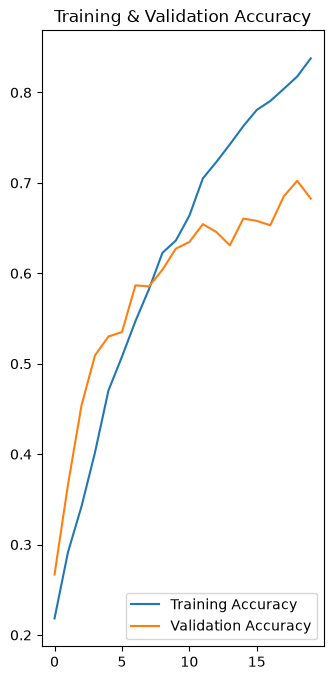

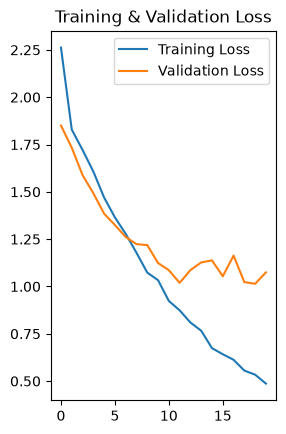

In [20]:
EPOCHS = 20
plt.figure(figsize=(8, 8))

plt.subplot(1, 2, 1)
plt.plot(range(EPOCHS), acc, label='Training Accuracy')
plt.plot(range(EPOCHS), val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training & Validation Accuracy')
plt.show()

plt.subplot(1, 2, 2)
plt.plot(range(EPOCHS), loss, label='Training Loss')
plt.plot(range(EPOCHS), val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training & Validation Loss')
plt.show()

**Step 21:** Saves the trained model, including its architecture and learned weights, to `Model.h5` for later reuse.

Note: Lưu model đã huấn luyện, gồm kiến trúc và trọng số đã học, vào `Model.h5` để sử dụng lại sau này.

In [21]:
model.save('Model.h5')

**Step 22:** Loads the saved model from `Model.h5` back into the `model` variable so it can make predictions without retraining.

In [22]:
model = load_model('Model.h5')

**Step 23:** Defines `predict_image`: it converts the input to a PIL image, resizes and normalizes it, adds a batch dimension, and asks the model for class probabilities. It then maps those values to the listed labels. The label order should match the training generator's class order exactly.

Note: Định nghĩa `predict_image`: chuyển ảnh đầu vào thành ảnh PIL, đổi kích thước và chuẩn hóa, thêm chiều batch rồi lấy xác suất từng lớp từ mô hình. Sau đó ghép xác suất với danh sách nhãn. Thứ tự nhãn cần khớp chính xác với thứ tự lớp của bộ train.

In [23]:

import numpy as np
from PIL import Image

def predict_image(img):

    # PIL Image
    if not isinstance(img, Image.Image):
        img = Image.fromarray(img)

    # Resize về đúng kích thước model
    img = img.resize((256, 256))

    # Convert PIL -> NumPy
    img = np.array(img)

    # Đảm bảo RGB 3 channels
    if img.shape[-1] == 4:
        img = img[:, :, :3]

    # Normalize giống lúc training
    img = img.astype("float32") / 255.0

    # Thêm batch dimension
    img_2d = np.expand_dims(img, axis=0)

    # Prediction
    prediction = model.predict(img_2d, verbose=0)[0]

    labels = [
        "Audi",
        "Hyundai Creta",
        "Mahindra Scorpio",
        "Rolls Royce",
        "Maruti Suzuki Swift",
        "Tata Safari",
        "Toyota Innova"
    ]

    # In ra để kiểm tra
    print("Prediction:", prediction)
    print("Sum:", np.sum(prediction))

    return {
        labels[i]: float(prediction[i])
        for i in range(len(labels))
    }

**Step 24:** Creates a Gradio interface where a user uploads an image and sees scores for up to seven car classes. `share=True` also requests a publicly shareable link while the interface is running.

Note: Tạo giao diện Gradio để người dùng tải ảnh lên và xem điểm.

In [24]:
image = gr.Image(type="pil")
label = gr.Label(num_top_classes=7)

gr.Interface(
    fn=predict_image,
    inputs=image,
    outputs=label
).launch(share=True)

* Running on local URL:  http://127.0.0.1:7860

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.
